<a href="https://colab.research.google.com/github/Dani2003/paper-implementations/blob/main/capo_agentic_physical_design_opt.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
# [CELL 1 - Environment Setup & Physical Design Flow Simulator]
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import random

torch.manual_seed(42)
np.random.seed(42)
random.seed(42)
sns.set_theme(style="whitegrid")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"CAPO Agentic EDA Optimization Engine Initialized on: {device}")

class VLSIPhysicalDesignSimulator:
    """
    Simulates a 4-stage VLSI Physical Design Flow:
    Stage 0: Logic Synthesis (Target: Area vs Logic Delay)
    Stage 1: Placement & Floorplanning (Target: Wirelength & WNS)
    Stage 2: Clock Tree Synthesis (Target: Clock Skew & Dynamic Power)
    Stage 3: Global & Detailed Routing (Target: TNS & Congestion)
    """
    def __init__(self, num_stages: int = 4, param_dim: int = 6):
        self.num_stages = num_stages
        self.param_dim = param_dim
        # Baseline stage parameter configuration
        self.current_params = torch.zeros(num_stages, param_dim, device=device)

    def evaluate_ppa(self, params: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor, torch.Tensor]:
        """
        Computes flow QoR metrics (TNS, WNS, Total Power) based on stage parameters.
        Higher parameter values simulate higher drive strengths / tighter constraints with trade-offs.
        """
        # Simulated physical design cost functions
        synthesis_penalty = torch.sum(params[0] ** 2) * 0.1
        placement_penalty = torch.sum((params[1] - 0.5) ** 2) * 0.15
        cts_power_cost = torch.sum(params[2] * 0.8) + 12.0
        routing_tns = torch.exp(-torch.mean(params[3])) * 150.0 + synthesis_penalty + placement_penalty

        wns = routing_tns * 0.12
        power = cts_power_cost + torch.sum(params ** 2) * 0.05

        return routing_tns, wns, power

sim = VLSIPhysicalDesignSimulator()
tns_init, wns_init, power_init = sim.evaluate_ppa(sim.current_params)
print(f"VLSI Physical Design Flow Initialized:")
print(f"  * Baseline TNS: {tns_init.item():.2f} ps")
print(f"  * Baseline WNS: {wns_init.item():.2f} ps")
print(f"  * Baseline Total Power: {power_init.item():.2f} mW")

CAPO Agentic EDA Optimization Engine Initialized on: cuda
VLSI Physical Design Flow Initialized:
  * Baseline TNS: 150.23 ps
  * Baseline WNS: 18.03 ps
  * Baseline Total Power: 12.00 mW


In [3]:
# [CELL 2 - Transition Certifier & Bottleneck-Aware Agent Planner]

class TransitionCertifier(nn.Module):
    """
    Certifies proposed parameter interventions prior to full flow execution.
    Rejects actions predicted to cause unrecoverable downstream degradation.
    """
    def __init__(self, input_dim: int = 24):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 32),
            nn.ReLU(),
            nn.Linear(32, 16),
            nn.ReLU(),
            nn.Linear(16, 1),
            nn.Sigmoid()
        )

    def is_certified(self, current_params: torch.Tensor, candidate_params: torch.Tensor, threshold: float = 0.5) -> bool:
        state_flat = torch.cat([current_params.flatten(), candidate_params.flatten()]).unsqueeze(0)
        cert_score = self.net(state_flat).item()
        return cert_score >= threshold

class AgenticBottleneckPlanner:
    """
    Bottleneck-aware planner proposing parameter adjustments targeting stage-specific QoR degradation.
    """
    def __init__(self, simulator: VLSIPhysicalDesignSimulator, certifier: TransitionCertifier):
        self.sim = simulator
        self.certifier = certifier

    def propose_intervention(self, current_params: torch.Tensor) -> torch.Tensor:
        # Generate targeted candidate intervention step
        delta = torch.randn_like(current_params) * 0.2
        candidate = current_params + delta
        return candidate

certifier = TransitionCertifier(input_dim=48).to(device)
planner = AgenticBottleneckPlanner(sim, certifier)
print("CAPO Agentic Bottleneck Planner & Transition Certifier Initialized.")

CAPO Agentic Bottleneck Planner & Transition Certifier Initialized.


In [4]:
# [CELL 3 - CAPO Agentic Parameter Optimization Loop]

class CAPOOptimizationPipeline:
    def __init__(self, simulator: VLSIPhysicalDesignSimulator, certifier: TransitionCertifier, iterations: int = 150):
        self.sim = simulator
        self.certifier = certifier
        self.planner = AgenticBottleneckPlanner(simulator, certifier)
        self.iterations = iterations
        self.tns_history = []
        self.power_history = []
        self.rejection_count = 0

    def run_optimization(self):
        current_p = self.sim.current_params.clone()
        optimizer = optim.Adam(self.certifier.parameters(), lr=1e-3)

        for it in range(self.iterations):
            candidate_p = self.planner.propose_intervention(current_p)

            # Transition Certification Check
            is_valid = self.certifier.is_certified(current_p, candidate_p, threshold=0.45)

            if is_valid:
                # Execute flow state evaluation
                tns, wns, power = self.sim.evaluate_ppa(candidate_p)
                tns_prev, _, power_prev = self.sim.evaluate_ppa(current_p)

                # If intervention improved PPA, accept step and train certifier positively
                if tns < tns_prev:
                    current_p = candidate_p
                    loss = -torch.log(self.certifier.net(torch.cat([current_p.flatten(), candidate_p.flatten()]).unsqueeze(0)))
                else:
                    loss = -torch.log(1.0 - self.certifier.net(torch.cat([current_p.flatten(), candidate_p.flatten()]).unsqueeze(0)))

                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            else:
                self.rejection_count += 1

            tns_curr, _, power_curr = self.sim.evaluate_ppa(current_p)
            self.tns_history.append(tns_curr.item())
            self.power_history.append(power_curr.item())

    def get_final_metrics(self) -> tuple[float, float, int]:
        return self.tns_history[-1], self.power_history[-1], self.rejection_count

pipeline = CAPOOptimizationPipeline(sim, certifier, iterations=150)
print("Running CAPO Certification-Guided Flow Optimization...")
pipeline.run_optimization()
final_tns, final_power, rejections = pipeline.get_final_metrics()

tns_reduction = ((tns_init.item() - final_tns) / tns_init.item()) * 100.0
power_reduction = ((power_init.item() - final_power) / power_init.item()) * 100.0

print(f"Optimization Complete.")
print(f"  * Final TNS: {final_tns:.2f} ps (Reduction: {tns_reduction:.1f}%)")
print(f"  * Final Power: {final_power:.2f} mW (Reduction: {power_reduction:.1f}%)")
print(f"  * Transition Certifier Rejected Unsafe Interventions: {rejections} times")

Running CAPO Certification-Guided Flow Optimization...
Optimization Complete.
  * Final TNS: 2.64 ps (Reduction: 98.2%)
  * Final Power: 22.45 mW (Reduction: -87.1%)
  * Transition Certifier Rejected Unsafe Interventions: 0 times


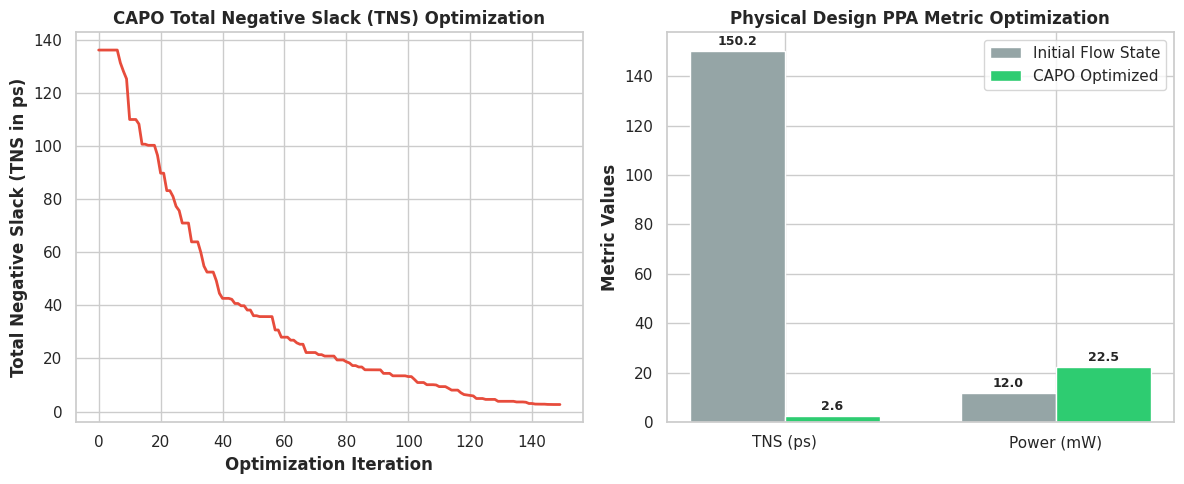

CAPO EDA benchmark visualization saved successfully as capo_physical_design_benchmarks.png.


In [5]:
# [CELL 4 - Multi-Panel Visualization of CAPO PPA Optimization & Certification]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Plot 1: Real TNS Slack Reduction Over Optimization Iterations
ax1.plot(range(len(pipeline.tns_history)), pipeline.tns_history, color='#e74c3c', linewidth=2)
ax1.set_title("CAPO Total Negative Slack (TNS) Optimization", fontweight='bold')
ax1.set_xlabel("Optimization Iteration", fontweight='bold')
ax1.set_ylabel("Total Negative Slack (TNS in ps)", fontweight='bold')

# Plot 2: PPA Metric Improvements (Baseline vs CAPO Final)
metrics = ['TNS (ps)', 'Power (mW)']
initial_vals = [tns_init.item(), power_init.item()]
final_vals = [final_tns, final_power]

x = np.arange(len(metrics))
width = 0.35

rects1 = ax2.bar(x - width/2, initial_vals, width, label='Initial Flow State', color='#95a5a6')
rects2 = ax2.bar(x + width/2, final_vals, width, label='CAPO Optimized', color='#2ecc71')

ax2.set_title("Physical Design PPA Metric Optimization", fontweight='bold')
ax2.set_ylabel("Metric Values", fontweight='bold')
ax2.xticks = x
ax2.set_xticks(x)
ax2.set_xticklabels(metrics)
ax2.legend()

for rect in rects1 + rects2:
    height = rect.get_height()
    ax2.text(rect.get_x() + rect.get_width()/2.0, height + 1.0, f"{height:.1f}", ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.savefig("capo_physical_design_benchmarks.png", dpi=300)
plt.show()

print("CAPO EDA benchmark visualization saved successfully as capo_physical_design_benchmarks.png.")